# Single-mode squeezing with the qubit + JC-sideband toolkit

**Task.** Prepare squeezed vacuum in the cavity with the qubit starting **and ending** in $g$. Target 8 dB, $r=8\ln10/20=0.921$; vacuum to $S(-r)\lvert0\rangle$, squeezed in $p$.

**Figure of merit.** The state fidelity $F=\lvert\langle g,S(-r)0\vert\psi_\text{out}\rangle\rvert^2$. It counts any population left in $e$ and any squeezing above or below 8 dB.

**Hardware rules**, the same as the rest of this folder:
- JC sideband with peak $|g|\le\pi/(2\cdot200\text{ ns})$;
- 30 ns qubit $\pi$ envelopes;
- CDs from the verified constant-pump family: $K$ cycles of $X\,X\,{-X}\,{-X}$, with $K=\lceil\max(2.5b,2.25b^2)\rceil\ge1$ and duration $(0.120K+0.010)$ µs (README).

A $\sigma_y$-conditioned CD, or one in the $p$ direction, is the same train in a rotated frame: qubit phase $+90°$ and sideband phase $+90°$, which costs no time.

**Results** (computed below):

| method | duration | squeezing reached | fidelity to 8 dB | model |
|---|---:|---:|---:|---|
| A. existing 160-pulse conditional squeeze, input $\lvert g,0\rangle$ | 4.81 µs | 8 dB | **0.9989** | SDK/RFDC samples, verified columns |
| B. Girvin gadget, ideal CDs, $a=0.30$, $\lambda=0.93$ | 4.42 µs | 8 dB | 0.9971 | ideal $\exp[(\beta a^\dagger-\beta^*a)\sigma]$ |
| B. Girvin gadget, ideal CDs, $a=0.30$, $\lambda=0.95$ | 5.20 µs | 8 dB | 0.9985 | ideal |
| B. Girvin gadget, **real** CDs (130 ns each), $a=0.30$, $\lambda=0.93$, schedule extended to 21 gadgets | 5.46 µs | 8 dB | 0.9974 | SDK/RFDC samples |

**Conclusion.** For single-mode squeezing use method A. It is the same gate as the conditional squeeze, and on $\lvert g\rangle$ it is exactly $S(r)$. It is faster and has the higher fidelity (4.81 µs, 0.9989).

The gadget of Singh, Royer and Girvin (PRX 16, 041018 (2026), Sec. IV B, App. D) is analytic and needs no gate optimization. Built from our verified 130 ns CDs, it reaches 8 dB at 0.9974 in 5.46 µs. Its advantage is that the protocol is simple and extends to any squeezing level. The real CDs squeeze a little less per gadget than ideal ones, so the device would calibrate the NUMBER of gadgets on measured squeezing, keeping the schedule fixed. Feeding back the state's $\langle x^2\rangle$ instead makes it stall (section 4).

## 0. Setup

Basis index $2n+q$ ($q=0$ is $g$), as in `code/cd_trains.py`. Ideal CD, in the same convention as the paper's Eq. (23) and this folder's README:
$$\mathrm{CD}(\beta,\sigma)=\exp\!\big[(\beta a^\dagger-\beta^*a)\,\sigma\big].$$

In [1]:
import sys, os, json
os.environ.setdefault("OPENBLAS_NUM_THREADS", "1")
import numpy as np
from scipy.linalg import expm
from scipy.optimize import brentq
import matplotlib.pyplot as plt

L = 96                                                 # Fock levels (8 dB squeezed vacuum needs < 60)
a = np.diag(np.sqrt(np.arange(1, L)), 1); ad = a.T
A, AD = np.kron(a, np.eye(2)), np.kron(ad, np.eye(2))
sx = np.array([[0, 1], [1, 0]]); sy = np.array([[0, -1j], [1j, 0]]); sz = np.diag([1.0, -1.0])
SX, SY = np.kron(np.eye(L), sx), np.kron(np.eye(L), sy)
X2 = (A + AD) @ (A + AD)                               # <x^2> with vacuum 1
P2 = -(AD - A) @ (AD - A)                              # <p^2> with vacuum 1

r8 = 8 * np.log(10) / 20
target = np.zeros(2 * L, complex)
target[0::2] = expm(-r8 / 2 * (a @ a - ad @ ad))[:, 0]   # |g> (x) S(-r)|0>: p squeezed by 8 dB

def cd_ideal(psi, beta, S):
    return expm((beta * AD - np.conj(beta) * A) @ S) @ psi

def T_cd(beta):                                        # verified constant-pump CD duration [us]
    K = max(1, int(np.ceil(max(2.5 * abs(beta), 2.25 * beta * beta) - 1e-12)))
    return 0.120 * K + 0.010

def moments(psi):                                      # Delta^2 = <x^2> and the p squeezing in dB
    return np.real(np.vdot(psi, X2 @ psi)), -10 * np.log10(np.real(np.vdot(psi, P2 @ psi)))

vac = np.zeros(2 * L, complex); vac[0] = 1
print(f"target: {moments(target)[1]:.3f} dB in p, <n> = {np.sinh(r8)**2:.3f}, norm {np.linalg.norm(target):.12f}")

target: 8.000 dB in p, <n> = 1.117, norm 1.000000000000


## 1. Method A: the conditional squeeze on $\lvert g\rangle$

The folder's 8 dB gate is $S_z(r)=\exp[\tfrac r2\sigma_z(a^2-a^{\dagger2})]$. With the qubit in $g$, $\sigma_z=+1$, so $S_z(r)\lvert g,\psi\rangle=\lvert g\rangle\,S(r)\lvert\psi\rangle$: a single-mode squeeze, and the qubit stays in $g$.

Its verified output columns (`runs/research_verified/squeeze_constant_reference_columns.npz`) come from the actual SDK words, the RFDC interpolator and cutoff-converged propagation. They are read here, not recomputed. Column 0 is the input $\lvert g,0\rangle$.

The target in that file is $S(+r)$: its $r>0$ squeezes $x$. The squeezed quadrature is only a frame choice, so the fidelity is taken against that file's own target.

In [2]:
z = np.load("../runs/research_verified/squeeze_constant_reference_columns.npz")
V, T = z["output"], z["target"]                        # 640 x 18 = (320 levels x 2) x (g0..g8, e0..e8)
f_col = [abs(np.vdot(T[:, m], V[:, m])) ** 2 for m in range(9)]
print(f"vacuum |g,0> -> state fidelity {f_col[0]:.5f};  population left in e {np.sum(abs(V[1::2, 0])**2):.2e}")
print("inputs |g,n>, n = 0..8:", np.round(f_col, 4))
print(f"g-subspace process fidelity (9 inputs) {abs(np.trace(T[:, :9].conj().T @ V[:, :9]))**2 / 81:.5f}; "
      f"all 18 inputs {abs(np.trace(T.conj().T @ V))**2 / 324:.5f} (README: 0.990183)")

vacuum |g,0> -> state fidelity 0.99892;  population left in e 4.75e-04
inputs |g,n>, n = 0..8: [0.9989 0.998  0.9967 0.9948 0.994  0.9937 0.9917 0.9831 0.9593]
g-subspace process fidelity (9 inputs) 0.98995; all 18 inputs 0.99018 (README: 0.990183)


## 2. Method B: the Girvin squeezing gadget

**The gadget** (PRX 16, 041018, Eq. 55 and App. D), for a state with $\Delta^2=\langle x^2\rangle$ (vacuum 1, $x=a+a^\dagger$):
$$S_k=\mathrm{CD}\!\big(i\lambda\alpha/\Delta^2,\sigma_y\big)\;\mathrm{CD}(\alpha,\sigma_x).$$

**Why it squeezes.** Read $\mathrm{CD}(\alpha,\sigma_x)=e^{-i\alpha\,p\,\sigma_x}$ (with $p=i(a^\dagger-a)$ here) as a qubit rotation that depends on the oscillator. On the oscillator's $x$ wavefunction it leaves the qubit with $\langle\sigma_x\rangle_x=\tanh(4\alpha x/\Delta^2)$ (App. D, in the paper's units). $\mathrm{CD}(i\gamma,\sigma_y)$ is a qubit rotation about $y$ by an angle linear in $x$. With $\gamma=\alpha/\Delta^2$ it undoes the linear part, so the qubit returns to $g$ up to $O(x^3)$. What remains on the oscillator is a small even cat, which is a slightly squeezed Gaussian. Repeating the gadget builds up squeezing.

**$\lambda$.** It scales the disentangling CD. The paper uses $\lambda=1$, plus a fitted slope correction. We scan $\lambda$: slightly under-correcting, $\lambda<1$, squeezes faster per gadget but leaves more residual entanglement.

**Timing.** Each gadget is two CDs. With our family, every CD with $b\le0.4$ is one cycle, 130 ns. The last gadget is trimmed so the squeezing lands exactly on 8.000 dB.

First, a sign check: one gadget from vacuum must return the qubit to $g$.

In [3]:
def gadget(psi, alpha, lam):
    D2 = moments(psi)[0]
    gamma = lam * alpha / D2
    return cd_ideal(cd_ideal(psi, alpha, SX), 1j * gamma, SY), (alpha, gamma)

for lam in (1.0, -1.0):
    out, _ = gadget(vac, 0.25, lam)
    print(f"one gadget, alpha 0.25, lambda {lam:+.0f}: P(g) = {np.sum(abs(out[0::2])**2):.5f}")

one gadget, alpha 0.25, lambda +1: P(g) = 0.99857
one gadget, alpha 0.25, lambda -1: P(g) = 0.78023


In [4]:
def run_ideal(alpha, lam, max_gadgets=120):
    psi, schedule = vac.copy(), []
    for k in range(max_gadgets):
        nxt, pair = gadget(psi, alpha, lam)
        if moments(nxt)[1] >= 8.0:                      # trim the last gadget onto 8.000 dB
            a_last = brentq(lambda s: moments(gadget(psi, s, lam)[0])[1] - 8.0, 1e-4, alpha, xtol=1e-7)
            psi, pair = gadget(psi, a_last, lam)
            schedule.append(pair)
            return psi, schedule
        psi = nxt
        schedule.append(pair)
    return psi, schedule

rows = []
for alpha in (0.30, 0.35):
    for lam in (0.90, 0.93, 0.95, 0.97, 1.00):
        psi, sched = run_ideal(alpha, lam)
        t = sum(T_cd(al) + T_cd(g) for al, g in sched)
        F = abs(np.vdot(target, psi)) ** 2
        rows.append((alpha, lam, len(sched), t, F))
        print(f"alpha {alpha:.2f} lambda {lam:.2f}: {len(sched):3d} gadgets, {t:5.2f} us, "
              f"{moments(psi)[1]:.3f} dB, F {F:.4f}, P(g) {np.sum(abs(psi[0::2])**2):.4f}")

alpha 0.30 lambda 0.90:  13 gadgets,  3.38 us, 8.000 dB, F 0.9933, P(g) 0.9952


alpha 0.30 lambda 0.93:  17 gadgets,  4.42 us, 8.000 dB, F 0.9971, P(g) 0.9984


alpha 0.30 lambda 0.95:  20 gadgets,  5.20 us, 8.000 dB, F 0.9985, P(g) 0.9993


alpha 0.30 lambda 0.97:  26 gadgets,  6.76 us, 8.000 dB, F 0.9986, P(g) 0.9994


alpha 0.30 lambda 1.00:  50 gadgets, 13.00 us, 8.000 dB, F 0.9971, P(g) 0.9972
alpha 0.35 lambda 0.90:  12 gadgets,  3.12 us, 8.000 dB, F 0.9929, P(g) 0.9968


alpha 0.35 lambda 0.93:  15 gadgets,  3.90 us, 8.000 dB, F 0.9958, P(g) 0.9986


alpha 0.35 lambda 0.95:  18 gadgets,  4.68 us, 8.000 dB, F 0.9969, P(g) 0.9991


alpha 0.35 lambda 0.97:  22 gadgets,  5.72 us, 8.000 dB, F 0.9969, P(g) 0.9991


alpha 0.35 lambda 1.00:  32 gadgets,  8.32 us, 8.000 dB, F 0.9972, P(g) 0.9992


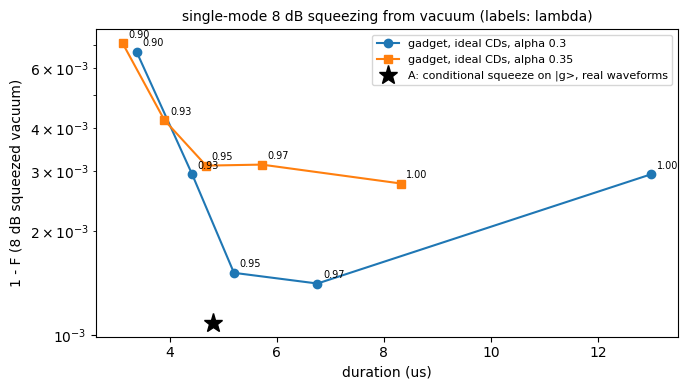

In [5]:
fig, ax = plt.subplots(figsize=(7, 4))
for alpha, mk in ((0.30, "o"), (0.35, "s")):
    pts = [(t, 1 - F, lam) for al, lam, n, t, F in rows if al == alpha]
    ax.plot([p[0] for p in pts], [p[1] for p in pts], mk + "-", label=f"gadget, ideal CDs, alpha {alpha}")
    for t, inf, lam in pts:
        ax.annotate(f"{lam:.2f}", (t, inf), textcoords="offset points", xytext=(4, 4), fontsize=7)
ax.plot([4.81], [1 - f_col[0]], "k*", ms=14, label="A: conditional squeeze on |g>, real waveforms")
ax.set_yscale("log"); ax.set_xlabel("duration (us)"); ax.set_ylabel("1 - F (8 dB squeezed vacuum)")
ax.set_title("single-mode 8 dB squeezing from vacuum (labels: lambda)", fontsize=10)
ax.legend(fontsize=8); plt.tight_layout(); plt.show()

## 3. Method B with the real CDs

Every CD is now played as the verified constant-pump binary-rule CD:
- the actual SDK words and RFDC samples (`code/verify_short_gates.arrays`);
- propagated sample by sample with `code/hardware_check.propagate`.

The $\sigma_y$ CD with imaginary amplitude is the same played train inside the frame $F=R_\text{cav}(\pi/2)\,e^{-i\pi\sigma_z/4}$; the check below confirms $F\,\mathrm{CD}(\gamma,\sigma_x)F^\dagger=\mathrm{CD}(i\gamma,\sigma_y)$.

Three ways to run it:
- **(i)** the ideal schedule as it is;
- **(ii)** the ideal schedule continued until the real state reaches 8 dB, with the last gadget trimmed. That is what a calibration on measured squeezing gives.
- **(iii)** adaptive: each $\gamma$ from the real state's own $\langle x^2\rangle$.

In [6]:
CODE = os.path.abspath("../code")
sys.path.insert(0, CODE)
_cwd = os.getcwd(); os.chdir(CODE)
import cd_trains as cd, hardware_check as hw
from verify_short_gates import arrays, OUT
os.chdir(_cwd)
base = json.loads((OUT / "cd_binary_n12_0.json").read_text())
lin = 2 / .365
COEF = float((np.pi / (2 * base["job"]["swap"]) / lin - 1) / lin ** 2)   # the family's one strength calibration

def cd_record(beta):
    b = abs(beta); cycles = max(1, int(np.ceil(max(2.5 * b, 2.25 * b * b) - 1e-12)))
    cells = 4 * cycles; linear = 2 * b / (cells * .03 + .005); g = linear * (1 + COEF * linear ** 2)
    pump = -np.pi / 2 + (np.pi if beta < 0 else 0)
    return dict(job=dict(name="gadget_cd", gate="cd", strength=beta, cells=cells, gap=0., swap=float(np.pi / (2 * g)),
                         pump_phase=pump, pump_control=False, cycles=cycles, calibration_coefficient=COEF),
                qubit_phases=np.resize([0., 0., np.pi, np.pi], cells).tolist(),
                pump_phases=np.full(cells, pump).tolist(), qubit_frame_Rz=0.)

_samples = {}
def cd_real(psi, beta):                                 # real beta, sigma_x conditioned, actual played samples
    key = round(beta, 9)
    if key not in _samples:
        q, s, *_ = arrays(cd_record(beta)); _samples[key] = (q, s)
    q, s = _samples[key]
    return hw.propagate(q, s, psi[:, None], cd.DT / 8, order=8, fast=True)[:, 0]

F = np.kron(expm(1j * np.pi / 2 * ad @ a), np.eye(2)) @ np.kron(np.eye(L), expm(-1j * np.pi / 4 * sz))
rng = np.random.default_rng(3); v = rng.normal(size=2 * L) + 1j * rng.normal(size=2 * L); v[24:] = 0; v /= np.linalg.norm(v)
print(f"frame check |F CD(g,sx) F^+ v - CD(ig,sy) v| = {np.linalg.norm(F @ cd_ideal(F.conj().T @ v, 0.2, SX) - cd_ideal(v, 0.2j, SY)):.1e}")
plus = np.zeros(2 * L, complex); plus[0] = plus[1] = 1 / np.sqrt(2)
for b in (0.1, 0.3):
    o = cd_real(plus, b)
    print(f"real CD {b}: fidelity to ideal from |0,g> {abs(np.vdot(cd_ideal(vac, b, SX), cd_real(vac, b)))**2:.6f}; "
          f"branch <a> {np.vdot(o, A @ o):.5f} (ideal {b})")

frame check |F CD(g,sx) F^+ v - CD(ig,sy) v| = 1.0e-15
real CD 0.1: fidelity to ideal from |0,g> 0.999985; branch <a> 0.10007+0.00006j (ideal 0.1)
real CD 0.3: fidelity to ideal from |0,g> 0.999871; branch <a> 0.30232+0.00163j (ideal 0.3)


In [7]:
def gadget_real(psi, alpha, gamma):
    return F @ cd_real(F.conj().T @ cd_real(psi, alpha), gamma)

print("(i) open loop, the ideal schedule played with real CDs:")
for alpha, lam in ((0.30, 0.93), (0.30, 0.95), (0.35, 1.00)):
    _, sched = run_ideal(alpha, lam)
    psi = vac.copy()
    for al, g in sched:
        psi = gadget_real(psi, al, g)
    print(f"  alpha {alpha:.2f} lambda {lam:.2f}: {len(sched)} gadgets -> {moments(psi)[1]:.3f} dB, "
          f"F(8 dB) {abs(np.vdot(target, psi))**2:.4f}, P(g) {np.sum(abs(psi[0::2])**2):.4f}")

print("(ii) the ideal schedule continued until the REAL state reaches 8 dB (last gadget trimmed):")
for alpha, lam in ((0.30, 0.93), (0.30, 0.95), (0.35, 0.93)):
    psi, sched, t = vac.copy(), [], 0.0
    ps = vac.copy()
    for k in range(40):                                  # the ideal schedule, further than 8 dB
        ps, pair = gadget(ps, alpha, lam); sched.append(pair)
    for k, (al, g) in enumerate(sched):
        prev = psi
        psi = gadget_real(psi, al, g); t += T_cd(al) + T_cd(g)
        if moments(psi)[1] >= 8.0:
            x = brentq(lambda x: moments(gadget_real(prev, x * al, x * g))[1] - 8.0, 0.01, 1.0, xtol=1e-5)
            psi = gadget_real(prev, x * al, x * g)
            print(f"  alpha {alpha:.2f} lambda {lam:.2f}: 8.000 dB after {k+1} gadgets, {t:.2f} us: "
                  f"F {abs(np.vdot(target, psi))**2:.4f}, P(g) {np.sum(abs(psi[0::2])**2):.4f}")
            break

print("(iii) adaptive (gamma from the real state's <x^2>), alpha 0.30, lambda 0.93, against the ideal run:")
psi_i, psi_r = vac.copy(), vac.copy()
for k in range(12):
    psi_i, _ = gadget(psi_i, 0.30, 0.93)
    psi_r = gadget_real(psi_r, 0.30, 0.93 * 0.30 / moments(psi_r)[0])
    if k % 2 == 1:
        print(f"  gadget {k+1:2d}: ideal {moments(psi_i)[1]:.3f} dB | real {moments(psi_r)[1]:.3f} dB, "
              f"P(g) {np.sum(abs(psi_r[0::2])**2):.4f}")

(i) open loop, the ideal schedule played with real CDs:


  alpha 0.30 lambda 0.93: 17 gadgets -> 7.004 dB, F(8 dB) 0.9938, P(g) 0.9990


  alpha 0.30 lambda 0.95: 20 gadgets -> 6.823 dB, F(8 dB) 0.9911, P(g) 0.9991


  alpha 0.35 lambda 1.00: 32 gadgets -> 6.759 dB, F(8 dB) 0.9861, P(g) 0.9970
(ii) the ideal schedule continued until the REAL state reaches 8 dB (last gadget trimmed):


  alpha 0.30 lambda 0.93: 8.000 dB after 21 gadgets, 5.46 us: F 0.9974, P(g) 0.9990


  alpha 0.30 lambda 0.95: 8.000 dB after 26 gadgets, 6.76 us: F 0.9967, P(g) 0.9982


  alpha 0.35 lambda 0.93: 8.000 dB after 22 gadgets, 5.72 us: F 0.9911, P(g) 0.9982
(iii) adaptive (gamma from the real state's <x^2>), alpha 0.30, lambda 0.93, against the ideal run:
  gadget  2: ideal 1.952 dB | real 1.833 dB, P(g) 0.9973
  gadget  4: ideal 3.114 dB | real 2.786 dB, P(g) 0.9961
  gadget  6: ideal 4.153 dB | real 3.486 dB, P(g) 0.9969


  gadget  8: ideal 5.074 dB | real 3.893 dB, P(g) 0.9949
  gadget 10: ideal 5.859 dB | real 4.073 dB, P(g) 0.9943
  gadget 12: ideal 6.577 dB | real 4.204 dB, P(g) 0.9936


## 4. Real CDs: less squeezing per gadget, and why the adaptive version stalls

- **Not the displacement size.** The real CDs displace each branch by within 1 % of $\beta$ (the check above).
- **Not a turned axis.** The squeezing ellipse stays on the $p$ axis; the full covariance was checked in the scratch study.
- **Less squeezing per gadget.** Each gadget relies on a second-order effect: the $\sigma_y$ CD cancels the linear part of the qubit's $x$-dependent rotation. Every 130 ns CD also carries its own small finite-pulse terms, a transverse $P_\phi\sigma_y$ piece and a conditional-squeezing piece. They enter at the order the gadget works in, so each real gadget squeezes a little less than an ideal one.
- **The state stays clean.** After the 17 ideal-schedule gadgets, run (i) gives 7.0 dB. Its fidelity to the 8 dB target, 0.9938, equals the overlap of a pure 7 dB and a pure 8 dB squeezed vacuum ($1/\cosh\Delta r=0.9934$). So the real state is very nearly pure squeezed vacuum, and four more gadgets reach 8 dB at 0.9974 (run ii).
- **Why (iii) stalls.** It sets $\gamma=\lambda\alpha/\langle x^2\rangle$ from the real state, whose small residual entanglement makes $\langle x^2\rangle$ larger than the $\Delta^2$ of the Gaussian the gadget assumes. $\gamma$ then under-corrects, entanglement grows further, and the squeezing stops near 4 dB. On the device, fix the schedule and calibrate only the number of gadgets (or the last one) on measured squeezing.
- **Two-cycle CDs (250 ns).** These are more accurate per CD (0.99997 from vacuum) but make every gadget twice as long, so they are slower than the 130 ns version.

**Not done here.** A faster single-mode squeeze could re-optimize method A's 160 qubit phases for the $g$ input only. The present gate is optimized for both qubit states, a stricter target. That is a gate optimization, left for the fast-gate study in `WORK_STATUS.md`.